# Task 2 – Data Preparation
## Neuaufbau mit erkennbaren Original-Lab-Codes und dem alten Projekt

Jeder Baustein zeigt zuerst die **tatsächliche Originalstelle**, danach den angepassten Code. Kleine Funktionen folgen dem alten Projekt; jede untersuchte Variante wird ausdrücklich aufgerufen. Es gibt keine Konfigurations-Engine, keine Zustandsverwaltung und keine verschachtelte Versuchsschleife.

**Beibehalten:** Task-1-Split (80/20, random_state=42), Baseline mit allen Originalfeatures, P95-Winsorisierung, negative Werte → P5 oder Imputation, getrennte Trainingsparameter, MAE/R², Kombinationen und drei CSV-Exporte. **Keine Präsentation** gemäß aktueller Anweisung.

**Ehrliche Herkunft:** P95/P5 sind keine wörtlichen Lab-Zellen. Ihre wenigen zusätzlichen Zeilen setzen den ausdrücklich besprochenen Tipp mit `.quantile()` und `.loc` um. Korrekturen am alten Projekt (insbesondere Trainingsstatistiken und konsistente Dummy-Referenz) sind gekennzeichnet.

Das Notebook im eigenen Ordner öffnen und von oben nach unten ausführen. Die beiden Rohdateien liegen direkt daneben. Alle fachlichen Quellen stammen aus eurem Projektordner.

## Aufgabenregeln und Versuchsplan

Maßgeblich: Case Study S. 8 und Feedback.md. Keine Feature Selection in Task 2; keine Änderung von Validierungs-/Testlabels und keine Zeilenlöschung aus diesen Datensätzen. Die Ein-Feature-Baseline aus Task 1b ist eine andere Aufgabe.

**Überschaubarer Kombinationsvergleich:** Zuerst alle 18 Kombinationen aus 2 Imputationen × 3 Ausreißerbehandlungen × 3 Negativwertbehandlungen. Danach Power, Windzyklus und Scaling jeweils allein auf der Baseline sowie alle 8 Kombinationen dieser drei Schritte auf der besten Grundvorbereitung (deren unveränderte Variante bereits zu den 18 gehört): **28 verschiedene Modelle**.

Das ist bewusst eine **stufenweise Auswahl**, keine erneute Vollsuche über 144 Varianten. Die beste Grundvorbereitung muss nicht die beste Grundlage für jede spätere Transformation sein. „Beste Variante“ bedeutet deshalb nur: beste der hier untersuchten 28 Varianten. Die Auswahl nutzt ausschließlich Validation-MAE; bei Rundungsunterschieden bis 10⁻⁸ die einfachere Variante.

Der Task-1-Zufallssplit mischt benachbarte Stunden; das kann optimistisch sein. Der offizielle Test ist aus den vorherigen Arbeiten bereits bekannt und kein neuer unberührter Holdout. Er wird in diesem Notebook erst nach der Auswahl geladen; keine Anpassung an dessen Ergebnis.

## 1. Imports

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 3 (0-basiert).

**Originalstelle:**
```python
import pandas as pd 
import numpy as np
```

**Notwendige Anpassung:** Unbenutzte Importe entfallen; PowerTransformer aus dem Transformations-Lab kommt hinzu.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler

## 2. Daten und Split

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 4 (0-basiert).

**Originalstelle:**
```python
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=42)
```

**Notwendige Anpassung:** PM2.5-Datei statt Bike Rental; der Testimport folgt erst nach der Auswahl. Fehlende Trainingslabels vor dem Split ausschließen wie Task 1, Zelle 14. Sonst exakt derselbe Split.

**Zusätzliche Originalstelle (Missing-Value-Demo, Zelle 20):**
```python
df=df.drop(df[df['target'].isnull()].index)
```
Nur auf die ursprüngliche Trainingsdatei anwenden. Nach dem Split bleibt Validation vollständig. Die 204 Ausschlüsse sind keine Imputation von Zielwerten.

In [2]:
df = pd.read_csv('pm25_train.csv')
missing_label_rows = df[df['pm25_target'].isnull()]
missing_label_rows.to_csv('ausgeschlossene_trainingszeilen.csv', index_label='source_row')
labeled = df.dropna(subset=['pm25_target']).copy()
train_df, val_df = train_test_split(labeled, test_size=0.2, random_state=42)
print('Training:', len(train_df), 'Validation:', len(val_df))
print('Vor dem Split ohne Label ausgeschlossen:', len(missing_label_rows))
# Originalindizes getrennt speichern; sie werden keine Modellfeatures.
train_df[['timestamp']].to_csv('zeilen_train.csv', index_label='source_row')
val_df[['timestamp']].to_csv('zeilen_validation.csv', index_label='source_row')
y_train = train_df['pm25_target'].copy()
y_val = val_df['pm25_target'].copy()

Training: 2727 Validation: 682
Vor dem Split ohne Label ausgeschlossen: 204


## 3. Trainingsdiagnose

**Quelle:** `Python Labs/04 - Missing Value Handling/Missing Value Handling_Demo.ipynb`, Codezelle 9 (0-basiert).

**Originalstelle:**
```python
#show descriptive statistics
df.describe()
```

**Notwendige Anpassung:** Nur den Fit-Trainingsteil untersuchen. Die Task-1-Exploration motiviert die Schritte, ihre Gesamtstatistiken werden aber nicht für Imputation oder Quantile übernommen.

,count,mean,std,min,25%,50%,75%,max
pm25_target,2727.0,3.330480,2.206418,0.240,1.7450,2.700,4.4600,14.710
pm25_lowcost,2464.0,5.606400,23.888014,0.300,1.7075,2.750,4.9000,595.530
no,2714.0,7.406780,41.985094,-2.700,0.4000,1.600,4.8750,1131.700
no2,2714.0,7.965917,6.398775,0.300,3.6000,7.000,10.7000,94.800
o3,2141.0,25.865624,13.634675,0.500,15.1000,24.600,35.1000,78.600
co2,1971.0,460.205530,22.410320,427.500,443.0500,455.700,473.3500,701.200
black_carbon,2727.0,0.887128,1.299725,0.045,0.3540,0.624,1.0280,36.684
ufp,2269.0,9452.169105,4862.980353,2077.700,6384.5000,8805.200,11620.0000,110138.800
temperature,2415.0,17.449595,4.983062,5.752,13.9630,17.006,20.8485,33.166
relative_humidity,2415.0,74.339289,14.099688,35.542,65.2690,77.536,85.7090,96.298


,Fehlende Werte
timestamp,0
year_month,0
pm25_target,0
pm25_lowcost,263
no,13
no2,13
o3,586
co2,756
black_carbon,0
ufp,458


Negative NO-Werte: 376


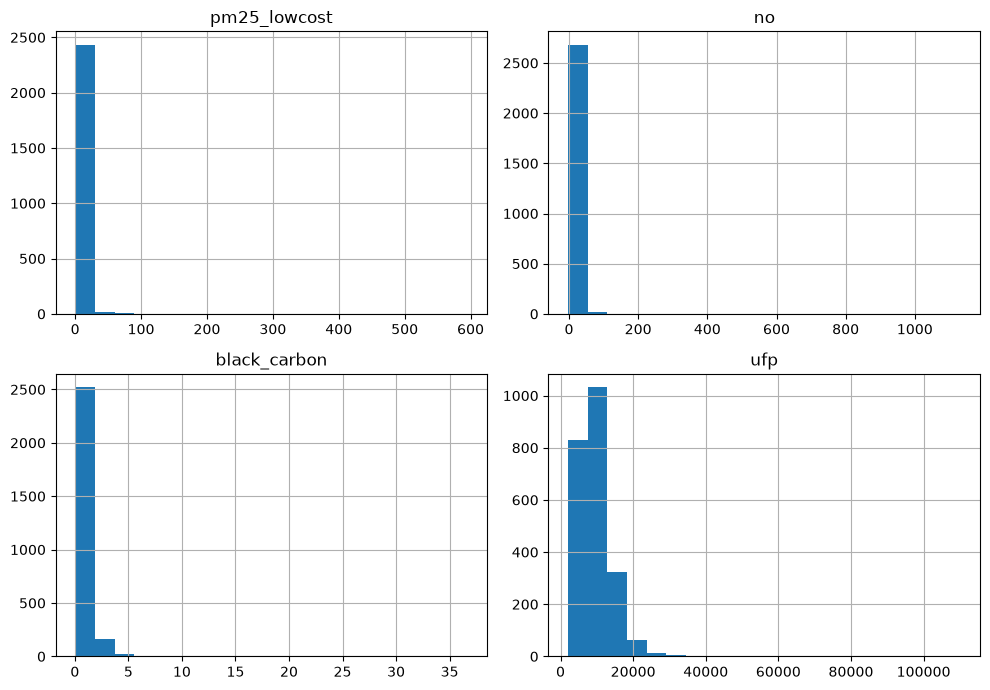

In [3]:
display(train_df.describe().T)
display(train_df.isnull().sum().to_frame('Fehlende Werte'))
print('Negative NO-Werte:', (train_df['no'] < 0).sum())
train_df[['pm25_lowcost', 'no', 'black_carbon', 'ufp']].hist(bins=20, figsize=(10, 7))
plt.tight_layout()
plt.savefig('trainingsverteilungen.png', bbox_inches='tight')
plt.show()

Task 1 identifiziert viele fehlende Messungen, starke Schadstoffspitzen und negative NO-Werte. Daraus folgen die hier geprüften Maßnahmen. Ein hoher Messwert ist nicht automatisch ein Fehler; Winsorisierung kann reale Spitzen abschneiden. Nullwerte von Regen/Strahlung werden nicht pauschal als Fehler markiert. Negative Temperatur wäre zulässig; die Negativregel gilt nur für Schadstofffeatures.

## 4. Technische Datumsumwandlung

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 7 (0-basiert).

**Originalstelle:**
```python
def rule_based(df):

    # Kopie erzeugen, damit wir den ursprünglichen Datensatz nicht verändern
    df = df.copy()
```

**Notwendige Anpassung:** Die Funktionsform und pd.to_datetime bleiben erhalten. Statt Wochentag/Saison wird timestamp als Tage seit Trainingsbeginn dargestellt. Diese Datumsdifferenz ist notwendiger Anpassungscode, keine wörtliche Lab-Stelle.

In [4]:
time_origin = pd.to_datetime(train_df['timestamp']).min()

def rule_based(df):
    df = df.copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df['timestamp'] = (df['timestamp'] - time_origin).dt.total_seconds() / 86400
    return df

train_numeric = rule_based(train_df.drop(columns='pm25_target'))
val_numeric = rule_based(val_df.drop(columns='pm25_target'))

## 5. One-Hot-Encoding

**Quelle:** `Python Labs/06 - Transformation/TRANSFORMATION_SCRIPT.ipynb`, Codezelle 3 (0-basiert).

**Originalstelle:**
```python
#one hot encoding of color, leave out one category to avoid dummy variable trap
color_oh_encoded = pd.get_dummies(df['Color'], prefix='Color', drop_first=True)
color_oh_encoded
```

**Notwendige Anpassung:** Color wird year_month. Ergänzend wird die Funktion one_hot_and_align aus dem alten Projekt, Zelle 21, übernommen und um die gemeinsame Referenzkategorie korrigiert.

**Korrektur gegenüber dem alten Projekt:** Zuerst alle Dummies bilden, dann das andere Dataset an die Trainingsspalten angleichen und **dieselbe Trainingsreferenz** aus beiden entfernen. Separates `drop_first=True` könnte bei fehlenden Kategorien unterschiedliche Referenzen erzeugen. Unbekannte Testmonate ergeben Nullen und sind damit nicht von der Referenz unterscheidbar; diese Einschränkung bleibt dokumentiert.

In [5]:
def one_hot_and_align(train_df, other_df):
    train_df = train_df.copy()
    other_df = other_df.copy()
    train_df = pd.get_dummies(train_df, columns=['year_month'], drop_first=False).astype(float)
    other_df = pd.get_dummies(other_df, columns=['year_month'], drop_first=False).astype(float)
    missed_columns = set(train_df.columns) - set(other_df.columns)
    for column in missed_columns:
        other_df[column] = 0
    extra_columns = set(other_df.columns) - set(train_df.columns)
    if extra_columns:
        other_df = other_df.drop(columns=list(extra_columns))
    other_df = other_df[train_df.columns]
    # Gemeinsame Referenz aus dem Training statt zwei unabhängiger Referenzen.
    month_columns = sorted([c for c in train_df.columns if c.startswith('year_month_')])
    reference = month_columns[0]
    train_df = train_df.drop(columns=reference)
    other_df = other_df.drop(columns=reference)
    return train_df, other_df

train_raw, val_raw = one_hot_and_align(train_numeric, val_numeric)
print('Alle 16 Originalfeatures sind enthalten bzw. numerisch repräsentiert:')
print(train_raw.columns.tolist())

Alle 16 Originalfeatures sind enthalten bzw. numerisch repräsentiert:
['timestamp', 'pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'rain_vol', 'glob_rad', 'year_month_2024-07', 'year_month_2024-08', 'year_month_2024-09', 'year_month_2024-10']


## 6. Fehlende Werte

**Quelle:** `Python Labs/04 - Missing Value Handling/Missing Value Handling_Demo.ipynb`, Codezelle 32 (0-basiert).

**Originalstelle:**
```python
df['random'].fillna(df['random'].mean(), inplace=True)
```

**Notwendige Anpassung:** Die Mittelwert-/Medianwerte werden vor dem Funktionsaufruf nur auf dem jeweiligen Training berechnet und an Validation weitergegeben. Funktionsform aus missing_value im alten Projekt, Zelle 14. Kein inplace=True, damit die Zuweisung zuverlässig auf dem DataFrame erfolgt.

In [6]:
def missing_value(df, replacement_values):
    df = df.copy()
    df = df.fillna(replacement_values)
    return df

## 7. Modell trainieren und bewerten

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 29 (0-basiert).

**Originalstelle:**
```python
def train_and_evaluate(X_train, y_train, X_val, y_val, name, log_dict):
    # Modell initialisieren und trainieren
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Vorhersage auf Validation
    y_pred = model.predict(X_val)

    # Kennzahlen
    mae = mean_absolute_error(y_val, y_pred)
    r2  = r2_score(y_val, y_pred)

    # Ausgabe
    print(f"Evaluation von {name}")
    print("MAE:", mae)
    print("R² :", r2)
    print()

    # Loggen
    log_dict[name] = {"MAE": mae, "R2": r2}

    return model
```

**Notwendige Anpassung:** Die alte train_and_evaluate-Funktion bleibt fast unverändert. Neu sind nur MAE/R² für Training und die Generalisierungslücke, wie in Task 2 verlangt.

In [7]:
def train_and_evaluate(X_train, y_train, X_val, y_val, name, log_dict):
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    train_pred = model.predict(X_train)
    train_mae = mean_absolute_error(y_train, train_pred)
    train_r2 = r2_score(y_train, train_pred)
    print(name, '| MAE:', round(mae, 4), '| R²:', round(r2, 4))
    log_dict[name] = {'MAE_Train': train_mae, 'R2_Train': train_r2,
                      'MAE_Validation': mae, 'R2_Validation': r2,
                      'MAE_Gap': mae - train_mae}
    return model

log_results = {}

## 8. Baseline

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 27 (0-basiert).

**Originalstelle:**
```python
X_train_base = X_train_base.fillna(X_train_base.mean())
X_val_base   = X_val_base.fillna(X_train_base.mean())
```

**Notwendige Anpassung:** Alle Originalfeatures statt nur drei ausgewählter Features; Mittelwerte explizit vor dem Auffüllen aus Training berechnen.

In [8]:
mean_raw = train_raw.mean()
train_mean = missing_value(train_raw, mean_raw)
val_mean = missing_value(val_raw, mean_raw)
baseline_model = train_and_evaluate(train_mean, y_train, val_mean, y_val,
                                    'Mittelwert', log_results)
baseline_mae = log_results['Mittelwert']['MAE_Validation']
baseline_r2 = log_results['Mittelwert']['R2_Validation']
print('Trainingslabel-Median:', y_train.median(), 'µg/m³')

Mittelwert | MAE: 1.2939 | R²: 0.4117
Trainingslabel-Median: 2.7 µg/m³


MAE ist eine Abweichung in µg/m³, keine Prozentgenauigkeit. R² misst die relative Güte im quadratischen Fehler und kann negativ sein. Die Baseline enthält nur notwendige Imputation und numerische Repräsentation; keine gezielte Ausreißerbehandlung oder Feature Selection.

## 9. Median als einzelne Maßnahme

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 14 (0-basiert).

**Originalstelle:**
```python
windspeed = df["windspeed"].median()
```

**Notwendige Anpassung:** Dieselbe Median-/fillna-Logik, auf alle Eingabefeatures angewendet. Den Trainingsmedian weiterreichen statt im Validierungsset neu berechnen.

In [9]:
median_raw = train_raw.median()
train_median = missing_value(train_raw, median_raw)
val_median = missing_value(val_raw, median_raw)
model_median = train_and_evaluate(train_median, y_train, val_median, y_val,
                                  'Median', log_results)

Median | MAE: 1.2984 | R²: 0.4077


## 10. Negative Werte und Winsorisierung

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 7 (0-basiert).

**Originalstelle:**
```python
df.loc[df["windspeed"] == -1, "windspeed"] = np.nan
```

**Notwendige Anpassung:** Die .loc-Regel und die kleine Funktion mit df.copy stammen aus dem alten Projekt. Die P5-/P95-Regeln selbst sind neu aus eurem Tipp. Quantile werden nur im Training berechnet.

**Keine behauptete Original-Lab-Kopie:** Die folgenden kurzen Funktionen sind die notwendige Umsetzung des Nutzerhinweises. Methodische Quelle: Outlier-Vorlesung S. 9 (Winsorisierung). `quantile` und Vergleichsmasken kommen auch im IQR-Lab vor.

P95 nur auf `pm25_lowcost`, niemals auf das Label. P5 pro Schadstofffeature nur aus nichtnegativen, beobachteten Trainingswerten. Nur **negative** Werte ersetzen; gültige kleine Werte bleiben erhalten. Die Alternative markiert negative Werte als NaN und imputiert anschließend.

In [10]:
pollutants = ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp']
p05 = train_raw[pollutants].where(train_raw[pollutants] >= 0).quantile(0.05)
p95 = train_raw['pm25_lowcost'].quantile(0.95)
print('NO-P5 ungefiltert:', train_raw['no'].quantile(0.05))
print('NO-P5 ohne negative Werte:', p05['no'])
print('PM2.5-P95:', p95)

def negative_p5(df, p05):
    df = df.copy()
    for column in pollutants:
        df.loc[df[column] < 0, column] = p05[column]
    return df

def negative_nan(df):
    df = df.copy()
    for column in pollutants:
        df.loc[df[column] < 0, column] = np.nan
    return df

def winsorisation(df, p95):
    df = df.copy()
    df.loc[df['pm25_lowcost'] > p95, 'pm25_lowcost'] = p95
    return df

train_p5 = negative_p5(train_raw, p05)
val_p5 = negative_p5(val_raw, p05)
train_nan = negative_nan(train_raw)
val_nan = negative_nan(val_raw)
train_winsor = winsorisation(train_raw, p95)
val_winsor = winsorisation(val_raw, p95)
train_p5_winsor = winsorisation(train_p5, p95)
val_p5_winsor = winsorisation(val_p5, p95)
train_nan_winsor = winsorisation(train_nan, p95)
val_nan_winsor = winsorisation(val_nan, p95)

NO-P5 ungefiltert: -0.6
NO-P5 ohne negative Werte: 0.1
PM2.5-P95: 11.315499999999997


## 11. IQR als Vergleich

**Quelle:** `Python Labs/XX - Building Pipelines for Data Preparation/Pipeline_Demo2_with_OutlierHandlingClass.ipynb`, Codezelle 3 (0-basiert).

**Originalstelle:**
```python
Q1 = X.quantile(0.25)
            Q3 = X.quantile(0.75)
            IQR = Q3 - Q1
            X[(X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))] = np.nan
```

**Notwendige Anpassung:** Nur den IQR-Zweig der Originalklasse als kleine Funktion verwenden. Grenzen separat im Training berechnen und übergeben, statt sie bei jedem transform auf Validation neu zu lernen.

In [11]:
def outlier_handling(df, lower, upper):
    df = df.copy()
    X = df[pollutants].copy()
    X[(X < lower) | (X > upper)] = np.nan
    df[pollutants] = X
    return df

Q1 = train_raw[pollutants].quantile(0.25)
Q3 = train_raw[pollutants].quantile(0.75)
IQR = Q3 - Q1
train_iqr = outlier_handling(train_raw, Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
val_iqr = outlier_handling(val_raw, Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

Q1_p5 = train_p5[pollutants].quantile(0.25)
Q3_p5 = train_p5[pollutants].quantile(0.75)
IQR_p5 = Q3_p5 - Q1_p5
train_p5_iqr = outlier_handling(train_p5, Q1_p5 - 1.5 * IQR_p5, Q3_p5 + 1.5 * IQR_p5)
val_p5_iqr = outlier_handling(val_p5, Q1_p5 - 1.5 * IQR_p5, Q3_p5 + 1.5 * IQR_p5)

Q1_nan = train_nan[pollutants].quantile(0.25)
Q3_nan = train_nan[pollutants].quantile(0.75)
IQR_nan = Q3_nan - Q1_nan
train_nan_iqr = outlier_handling(train_nan, Q1_nan - 1.5 * IQR_nan, Q3_nan + 1.5 * IQR_nan)
val_nan_iqr = outlier_handling(val_nan, Q1_nan - 1.5 * IQR_nan, Q3_nan + 1.5 * IQR_nan)

## 12. Sichtbare Einzeltests und Kombinationen

**Quelle für jeden folgenden Block:** Missing-Value-Demo, Zelle 32 (`fillna`); altes Notebook, Zellen 14, 29 und 32–34 (kleine Funktionen ausdrücklich nacheinander aufrufen und bewerten).

**Anpassung:** Die vorbereiteten Datenpaare aus Abschnitt 10/11 werden mit Trainingsmittelwert oder Trainingsmedian ergänzt. Es folgen acht Datenpaare mit je zwei Imputationen. Zusammen mit Baseline und Median allein sind das alle **18 Grundkombinationen**. IQR und Winsor werden nicht doppelt auf dieselben Spitzen angewendet.

### Neg-P5
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [12]:
mean_p5 = train_p5.mean()
train_p5_mean = missing_value(train_p5, mean_p5)
val_p5_mean = missing_value(val_p5, mean_p5)
model_p5_mean = train_and_evaluate(train_p5_mean, y_train, val_p5_mean, y_val,
                                      'Mittelwert + Neg-P5', log_results)

median_p5 = train_p5.median()
train_p5_median = missing_value(train_p5, median_p5)
val_p5_median = missing_value(val_p5, median_p5)
model_p5_median = train_and_evaluate(train_p5_median, y_train, val_p5_median, y_val,
                                        'Median + Neg-P5', log_results)

Mittelwert + Neg-P5 | MAE: 1.2932 | R²: 0.4122
Median + Neg-P5 | MAE: 1.2978 | R²: 0.4082


### Neg-Imputation
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [13]:
mean_nan = train_nan.mean()
train_nan_mean = missing_value(train_nan, mean_nan)
val_nan_mean = missing_value(val_nan, mean_nan)
model_nan_mean = train_and_evaluate(train_nan_mean, y_train, val_nan_mean, y_val,
                                      'Mittelwert + Neg-Imputation', log_results)

median_nan = train_nan.median()
train_nan_median = missing_value(train_nan, median_nan)
val_nan_median = missing_value(val_nan, median_nan)
model_nan_median = train_and_evaluate(train_nan_median, y_train, val_nan_median, y_val,
                                        'Median + Neg-Imputation', log_results)

Mittelwert + Neg-Imputation | MAE: 1.2918 | R²: 0.414
Median + Neg-Imputation | MAE: 1.2972 | R²: 0.4087


### Winsor-P95
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [14]:
mean_winsor = train_winsor.mean()
train_winsor_mean = missing_value(train_winsor, mean_winsor)
val_winsor_mean = missing_value(val_winsor, mean_winsor)
model_winsor_mean = train_and_evaluate(train_winsor_mean, y_train, val_winsor_mean, y_val,
                                      'Mittelwert + Winsor-P95', log_results)

median_winsor = train_winsor.median()
train_winsor_median = missing_value(train_winsor, median_winsor)
val_winsor_median = missing_value(val_winsor, median_winsor)
model_winsor_median = train_and_evaluate(train_winsor_median, y_train, val_winsor_median, y_val,
                                        'Median + Winsor-P95', log_results)

Mittelwert + Winsor-P95 | MAE: 0.9336 | R²: 0.6589
Median + Winsor-P95 | MAE: 0.9296 | R²: 0.6579


### IQR
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [15]:
mean_iqr = train_iqr.mean()
train_iqr_mean = missing_value(train_iqr, mean_iqr)
val_iqr_mean = missing_value(val_iqr, mean_iqr)
model_iqr_mean = train_and_evaluate(train_iqr_mean, y_train, val_iqr_mean, y_val,
                                      'Mittelwert + IQR', log_results)

median_iqr = train_iqr.median()
train_iqr_median = missing_value(train_iqr, median_iqr)
val_iqr_median = missing_value(val_iqr, median_iqr)
model_iqr_median = train_and_evaluate(train_iqr_median, y_train, val_iqr_median, y_val,
                                        'Median + IQR', log_results)

Mittelwert + IQR | MAE: 0.9727 | R²: 0.6082
Median + IQR | MAE: 1.0149 | R²: 0.5757


### Neg-P5 + Winsor-P95
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [16]:
mean_p5_winsor = train_p5_winsor.mean()
train_p5_winsor_mean = missing_value(train_p5_winsor, mean_p5_winsor)
val_p5_winsor_mean = missing_value(val_p5_winsor, mean_p5_winsor)
model_p5_winsor_mean = train_and_evaluate(train_p5_winsor_mean, y_train, val_p5_winsor_mean, y_val,
                                      'Mittelwert + Neg-P5 + Winsor-P95', log_results)

median_p5_winsor = train_p5_winsor.median()
train_p5_winsor_median = missing_value(train_p5_winsor, median_p5_winsor)
val_p5_winsor_median = missing_value(val_p5_winsor, median_p5_winsor)
model_p5_winsor_median = train_and_evaluate(train_p5_winsor_median, y_train, val_p5_winsor_median, y_val,
                                        'Median + Neg-P5 + Winsor-P95', log_results)

Mittelwert + Neg-P5 + Winsor-P95 | MAE: 0.9334 | R²: 0.6591


Median + Neg-P5 + Winsor-P95 | MAE: 0.9294 | R²: 0.6581


### Neg-Imputation + Winsor-P95
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [17]:
mean_nan_winsor = train_nan_winsor.mean()
train_nan_winsor_mean = missing_value(train_nan_winsor, mean_nan_winsor)
val_nan_winsor_mean = missing_value(val_nan_winsor, mean_nan_winsor)
model_nan_winsor_mean = train_and_evaluate(train_nan_winsor_mean, y_train, val_nan_winsor_mean, y_val,
                                      'Mittelwert + Neg-Imputation + Winsor-P95', log_results)

median_nan_winsor = train_nan_winsor.median()
train_nan_winsor_median = missing_value(train_nan_winsor, median_nan_winsor)
val_nan_winsor_median = missing_value(val_nan_winsor, median_nan_winsor)
model_nan_winsor_median = train_and_evaluate(train_nan_winsor_median, y_train, val_nan_winsor_median, y_val,
                                        'Median + Neg-Imputation + Winsor-P95', log_results)

Mittelwert + Neg-Imputation + Winsor-P95 | MAE: 0.9323 | R²: 0.6597
Median + Neg-Imputation + Winsor-P95 | MAE: 0.9289 | R²: 0.6583


### Neg-P5 + IQR
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [18]:
mean_p5_iqr = train_p5_iqr.mean()
train_p5_iqr_mean = missing_value(train_p5_iqr, mean_p5_iqr)
val_p5_iqr_mean = missing_value(val_p5_iqr, mean_p5_iqr)
model_p5_iqr_mean = train_and_evaluate(train_p5_iqr_mean, y_train, val_p5_iqr_mean, y_val,
                                      'Mittelwert + Neg-P5 + IQR', log_results)

median_p5_iqr = train_p5_iqr.median()
train_p5_iqr_median = missing_value(train_p5_iqr, median_p5_iqr)
val_p5_iqr_median = missing_value(val_p5_iqr, median_p5_iqr)
model_p5_iqr_median = train_and_evaluate(train_p5_iqr_median, y_train, val_p5_iqr_median, y_val,
                                        'Median + Neg-P5 + IQR', log_results)

Mittelwert + Neg-P5 + IQR | MAE: 0.9718 | R²: 0.6089


Median + Neg-P5 + IQR | MAE: 1.0138 | R²: 0.5768


### Neg-Imputation + IQR
**Quelle:** Missing-Value-Demo Zelle 32; altes Projekt Zellen 14 und 29. Nur Variablennamen und Modellbezeichnung angepasst. Trainingsstatistiken bleiben getrennt von Validation.

In [19]:
mean_nan_iqr = train_nan_iqr.mean()
train_nan_iqr_mean = missing_value(train_nan_iqr, mean_nan_iqr)
val_nan_iqr_mean = missing_value(val_nan_iqr, mean_nan_iqr)
model_nan_iqr_mean = train_and_evaluate(train_nan_iqr_mean, y_train, val_nan_iqr_mean, y_val,
                                      'Mittelwert + Neg-Imputation + IQR', log_results)

median_nan_iqr = train_nan_iqr.median()
train_nan_iqr_median = missing_value(train_nan_iqr, median_nan_iqr)
val_nan_iqr_median = missing_value(val_nan_iqr, median_nan_iqr)
model_nan_iqr_median = train_and_evaluate(train_nan_iqr_median, y_train, val_nan_iqr_median, y_val,
                                        'Median + Neg-Imputation + IQR', log_results)

Mittelwert + Neg-Imputation + IQR | MAE: 0.973 | R²: 0.6083
Median + Neg-Imputation + IQR | MAE: 1.0155 | R²: 0.5758


## 13. Grundkombinationen vergleichen

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 38 (0-basiert).

**Originalstelle:**
```python
pd.DataFrame(log_results)
```

**Notwendige Anpassung:** Log wie im alten Projekt in einen DataFrame umwandeln; Zeilen statt Spalten pro Modell, MAE-Sortierung und Deltas ergänzen.

In [20]:
core_results = pd.DataFrame(log_results).T
core_results['MAE_Gewinn_abs'] = baseline_mae - core_results['MAE_Validation']
core_results['MAE_Gewinn_pct'] = 100 * core_results['MAE_Gewinn_abs'] / baseline_mae
core_results['R2_Delta'] = core_results['R2_Validation'] - baseline_r2
display(core_results.sort_values('MAE_Validation'))
core_results.to_csv('grundkombinationen.csv', index_label='Modell')
print('Beste Grundvorbereitung:', core_results['MAE_Validation'].idxmin())

,MAE_Train,R2_Train,MAE_Validation,R2_Validation,MAE_Gap,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
Median + Neg-Imputation + Winsor-P95,0.894925,0.660433,0.928889,0.658346,0.033963,0.364992,28.209093,0.246657
Median + Neg-P5 + Winsor-P95,0.894988,0.660203,0.929379,0.658092,0.034391,0.364502,28.171214,0.246404
Median + Winsor-P95,0.895244,0.660005,0.929644,0.657916,0.034400,0.364237,28.150737,0.246228
Mittelwert + Neg-Imputation + Winsor-P95,0.900433,0.659346,0.932337,0.659681,0.031905,0.361544,27.942570,0.247993
Mittelwert + Neg-P5 + Winsor-P95,0.899806,0.658873,0.933383,0.659087,0.033576,0.360498,27.861767,0.247399
Mittelwert + Winsor-P95,0.900030,0.658684,0.933646,0.658922,0.033616,0.360235,27.841451,0.247234
Mittelwert + Neg-P5 + IQR,0.951137,0.583544,0.971828,0.608875,0.020690,0.322053,24.890462,0.197186
Mittelwert + IQR,0.951849,0.583316,0.972716,0.608190,0.020867,0.321164,24.821798,0.196501
Mittelwert + Neg-Imputation + IQR,0.952497,0.583400,0.972991,0.608330,0.020495,0.320889,24.800530,0.196641
Median + Neg-P5 + IQR,0.991752,0.549653,1.013773,0.576841,0.022021,0.280107,21.648621,0.165153


Beste Grundvorbereitung: Median + Neg-Imputation + Winsor-P95


## 14. Beste Grundvorbereitung ausdrücklich weiterverwenden

**Quelle:** altes Projekt Zellen 31–34 (benannte Zwischenstände weiterreichen). **Anpassung:** Nicht automatisch den letzten Schritt nehmen, sondern die oben verglichenen Ergebnisse beachten.

Auf dem vorliegenden Split gewinnt `Median + Neg-Imputation + Winsor-P95`. Genau diese Variablen werden unten ausdrücklich übernommen. Die Prüfung verhindert, dass bei geänderten Daten unbemerkt ein alter Sieger weiterverwendet wird. Falls sie fehlschlägt, den Vergleich oben lesen und die benannten Datenpaare anpassen; es gibt bewusst keine automatische Pipeline-Steuerung.

In [21]:
core_name = 'Median + Neg-Imputation + Winsor-P95'
assert core_results['MAE_Validation'].idxmin() == core_name
train_core = train_nan_winsor_median.copy()
val_core = val_nan_winsor_median.copy()

## 15. Power-Transformation

**Quelle:** `Python Labs/06 - Transformation/TRANSFORMATION_SCRIPT.ipynb`, Codezelle 41 (0-basiert).

**Originalstelle:**
```python
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(standardize=False)
trans_x= pt.fit_transform(np.array(df['petal length (cm)'].array.reshape(-1, 1)))

df['petal length (cm) ptransformed']=trans_x

df['petal length (cm) ptransformed'].hist(bins=20,figsize=(5, 5))
#Does not work in this example - skew is not clear enough
```

**Notwendige Anpassung:** Dieselbe PowerTransformer-Klasse und standardize=False. Kleine train/apply-Funktionen nach scale_train/scale_apply aus dem alten Projekt, Zelle 24. Nur im Training fitten; identische Spalten in Validation transformieren.

In [22]:
# Vorab nur aus Trainingsschiefe wählen; keine Feature Selection.
sensor_columns = ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp',
                  'temperature', 'relative_humidity', 'pressure', 'wind_speed',
                  'wind_direction', 'rain_vol', 'glob_rad']
power_columns = [c for c in sensor_columns if c != 'wind_direction' and abs(train_raw[c].skew()) > 1]
print('Power-Spalten (Trainingsschiefe > 1):', power_columns)

def power_train(df):
    df = df.copy()
    pt = PowerTransformer(standardize=False)
    df[power_columns] = pt.fit_transform(df[power_columns])
    return df, pt

def power_apply(df, pt):
    df = df.copy()
    df[power_columns] = pt.transform(df[power_columns])
    return df

train_power, pt_baseline = power_train(train_mean)
val_power = power_apply(val_mean, pt_baseline)
model_power = train_and_evaluate(train_power, y_train, val_power, y_val,
                                 'Mittelwert + Power', log_results)

Power-Spalten (Trainingsschiefe > 1): ['pm25_lowcost', 'no', 'no2', 'co2', 'black_carbon', 'ufp', 'wind_speed', 'glob_rad']


Mittelwert + Power | MAE: 0.9072 | R²: 0.6831


## 16. Windrichtung zyklisch

**Quelle:** `Python Labs/06 - Transformation/TRANSFORMATION_SCRIPT.ipynb`, Codezelle 16 (0-basiert).

**Originalstelle:**
```python
#Demonstrate cyclic encoding of Month feature
df_cyclic_encoding['Month_sin'] = np.sin(2 * np.pi * df_cyclic_encoding['Month']/12)
df_cyclic_encoding['Month_cos'] = np.cos(2 * np.pi * df_cyclic_encoding['Month']/12)
df_cyclic_encoding
```

**Notwendige Anpassung:** Windrichtung statt Monat; 360 statt 12. Die Winkelkomponenten ersetzen das Rohfeature, keine Auswahl nach Korrelation. Grad wird aus dem Wertebereich angenommen. Eine kleine df.copy-Funktion folgt dem alten rule_based-Muster.

In [23]:
def wind_cyclic(df):
    df = df.copy()
    df['wind_direction_sin'] = np.sin(2 * np.pi * df['wind_direction'] / 360)
    df['wind_direction_cos'] = np.cos(2 * np.pi * df['wind_direction'] / 360)
    df = df.drop(columns='wind_direction')
    return df

train_wind = wind_cyclic(train_mean)
val_wind = wind_cyclic(val_mean)
model_wind = train_and_evaluate(train_wind, y_train, val_wind, y_val,
                                'Mittelwert + Windzyklus', log_results)

Mittelwert + Windzyklus | MAE: 1.28 | R²: 0.4257


**Bewusste Vereinfachung der Reihenfolge:** Erst fehlende Rohwinkel mit der jeweiligen Trainingsstatistik auffüllen, danach die Lab-Formel auf vollständige Werte anwenden. Dadurch bleibt das Vorgehen leicht nachvollziehbar. Ein Mittelwert von Winkeln ist nahe 0°/360° nicht ideal; diese Grenze wird nicht verschwiegen. Die zyklische Darstellung wird als Versuch bewertet, nicht als zwangsläufig bessere Variante.

## 17. Standardisierung

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 24 (0-basiert).

**Originalstelle:**
```python
# Liste der numerischen Features, die wirklich skaliert werden sollen:
to_scale = ["instant", "atemp", "hum", "windspeed"]

def scale_train(df):
    df = df.copy()

    # Scaler initialisieren
    scaler = StandardScaler()

    # Fit + Transform auf Trainingsdaten
    df[to_scale] = scaler.fit_transform(df[to_scale])

    return df, scaler

def scale_apply(df, scaler):
    df = df.copy()

    # Transform auf Validation/Test anwenden
    df[to_scale] = scaler.transform(df[to_scale])

    return df

log_results = {}
```

**Notwendige Anpassung:** Die beiden Funktionen scale_train/scale_apply bleiben erhalten. Spaltenliste wird als Argument übergeben, damit Rohwind oder Sinus/Cosinus korrekt skalierbar sind; Monatsdummies werden nicht skaliert.

**Lab-Bezug:** `Python Labs/07 - Scaling/SCALING.ipynb`, Zelle 6: `scaler = preprocessing.StandardScaler()`, `scaler.fit(data)`, `scaler.transform(data)`. Es wird exakt dieses Fit/Transform-Prinzip verwendet.

In [24]:
def scale_train(df, to_scale):
    df = df.copy()
    scaler = StandardScaler()
    df[to_scale] = scaler.fit_transform(df[to_scale])
    return df, scaler

def scale_apply(df, scaler, to_scale):
    df = df.copy()
    df[to_scale] = scaler.transform(df[to_scale])
    return df

to_scale = ['timestamp'] + sensor_columns
to_scale_wind = [c for c in to_scale if c != 'wind_direction'] + ['wind_direction_sin', 'wind_direction_cos']
train_scaled, scaler_baseline = scale_train(train_mean, to_scale)
val_scaled = scale_apply(val_mean, scaler_baseline, to_scale)
model_scaled = train_and_evaluate(train_scaled, y_train, val_scaled, y_val,
                                  'Mittelwert + Scaling', log_results)

Mittelwert + Scaling | MAE: 1.2939 | R²: 0.4117


## 18. Alle Transformationen auf der besten Grundvorbereitung kombinieren

**Quelle:** Transformation-Script Zellen 16/41, Scaling-Lab Zelle 6; explizite Modulaufrufe aus altem Projekt Zellen 31–34.

**Anpassung:** Statt versteckter Optionen sind alle sieben zusätzlichen Kombinationen ausgeschrieben. Ohne Transformation ist `train_core` schon bewertet. Die Reihenfolge bleibt Power → Wind → Scaling. Jeder Transformer wird auf seinem Trainingszwischenstand gefittet, niemals auf Validation.

In [25]:
train_core_power, pt_core = power_train(train_core)
val_core_power = power_apply(val_core, pt_core)
model_core_power = train_and_evaluate(train_core_power, y_train, val_core_power, y_val,
                                      core_name + ' + Power', log_results)

train_core_wind = wind_cyclic(train_core)
val_core_wind = wind_cyclic(val_core)
model_core_wind = train_and_evaluate(train_core_wind, y_train, val_core_wind, y_val,
                                     core_name + ' + Windzyklus', log_results)

train_core_scaled, scaler_core = scale_train(train_core, to_scale)
val_core_scaled = scale_apply(val_core, scaler_core, to_scale)
model_core_scaled = train_and_evaluate(train_core_scaled, y_train, val_core_scaled, y_val,
                                       core_name + ' + Scaling', log_results)

train_core_power_wind = wind_cyclic(train_core_power)
val_core_power_wind = wind_cyclic(val_core_power)
model_core_power_wind = train_and_evaluate(train_core_power_wind, y_train, val_core_power_wind, y_val,
                                           core_name + ' + Power + Windzyklus', log_results)

train_core_power_scaled, scaler_core_power = scale_train(train_core_power, to_scale)
val_core_power_scaled = scale_apply(val_core_power, scaler_core_power, to_scale)
model_core_power_scaled = train_and_evaluate(train_core_power_scaled, y_train, val_core_power_scaled, y_val,
                                             core_name + ' + Power + Scaling', log_results)

train_core_wind_scaled, scaler_core_wind = scale_train(train_core_wind, to_scale_wind)
val_core_wind_scaled = scale_apply(val_core_wind, scaler_core_wind, to_scale_wind)
model_core_wind_scaled = train_and_evaluate(train_core_wind_scaled, y_train, val_core_wind_scaled, y_val,
                                            core_name + ' + Windzyklus + Scaling', log_results)

train_core_power_wind_scaled, scaler_core_power_wind = scale_train(train_core_power_wind, to_scale_wind)
val_core_power_wind_scaled = scale_apply(val_core_power_wind, scaler_core_power_wind, to_scale_wind)
model_core_all = train_and_evaluate(train_core_power_wind_scaled, y_train, val_core_power_wind_scaled, y_val,
                                    core_name + ' + Power + Windzyklus + Scaling', log_results)

Median + Neg-Imputation + Winsor-P95 + Power | MAE: 0.8499 | R²: 0.7273
Median + Neg-Imputation + Winsor-P95 + Windzyklus | MAE: 0.9327 | R²: 0.662
Median + Neg-Imputation + Winsor-P95 + Scaling | MAE: 0.9289 | R²: 0.6583
Median + Neg-Imputation + Winsor-P95 + Power + Windzyklus | MAE: 0.8563 | R²: 0.7305
Median + Neg-Imputation + Winsor-P95 + Power + Scaling | MAE: 0.8499 | R²: 0.7273


Median + Neg-Imputation + Winsor-P95 + Windzyklus + Scaling | MAE: 0.9327 | R²: 0.662
Median + Neg-Imputation + Winsor-P95 + Power + Windzyklus + Scaling | MAE: 0.8563 | R²: 0.7305


## 19. Gesamtergebnis und Diagramme

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 38 (0-basiert).

**Originalstelle:**
```python
pd.DataFrame(log_results)
```

**Notwendige Anpassung:** Log-DataFrame wie im Original; Deltas und Balkendiagramme mit Pandas/Matplotlib entsprechend Feedback. Die Grafiken haben denselben Datensatz als Vergleichsbasis.

,MAE_Train,R2_Train,MAE_Validation,R2_Validation,MAE_Gap,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
Median + Neg-Imputation + Winsor-P95 + Power + Scaling,0.821185,0.731913,0.849933,0.727292,0.028749,4.439474e-01,3.431131e+01,3.156040e-01
Median + Neg-Imputation + Winsor-P95 + Power,0.821185,0.731913,0.849933,0.727292,0.028749,4.439474e-01,3.431131e+01,3.156040e-01
Median + Neg-Imputation + Winsor-P95 + Power + Windzyklus,0.825921,0.732278,0.856275,0.730463,0.030353,4.376060e-01,3.382120e+01,3.187749e-01
Median + Neg-Imputation + Winsor-P95 + Power + Windzyklus + Scaling,0.825921,0.732278,0.856275,0.730463,0.030353,4.376060e-01,3.382120e+01,3.187749e-01
Mittelwert + Power,0.879531,0.684708,0.907182,0.683095,0.027652,3.866983e-01,2.988670e+01,2.714067e-01
Median + Neg-Imputation + Winsor-P95,0.894925,0.660433,0.928889,0.658346,0.033963,3.649920e-01,2.820909e+01,2.466574e-01
Median + Neg-Imputation + Winsor-P95 + Scaling,0.894925,0.660433,0.928889,0.658346,0.033963,3.649920e-01,2.820909e+01,2.466574e-01
Median + Neg-P5 + Winsor-P95,0.894988,0.660203,0.929379,0.658092,0.034391,3.645019e-01,2.817121e+01,2.464037e-01
Median + Winsor-P95,0.895244,0.660005,0.929644,0.657916,0.034400,3.642370e-01,2.815074e+01,2.462278e-01
Mittelwert + Neg-Imputation + Winsor-P95,0.900433,0.659346,0.932337,0.659681,0.031905,3.615435e-01,2.794257e+01,2.479927e-01


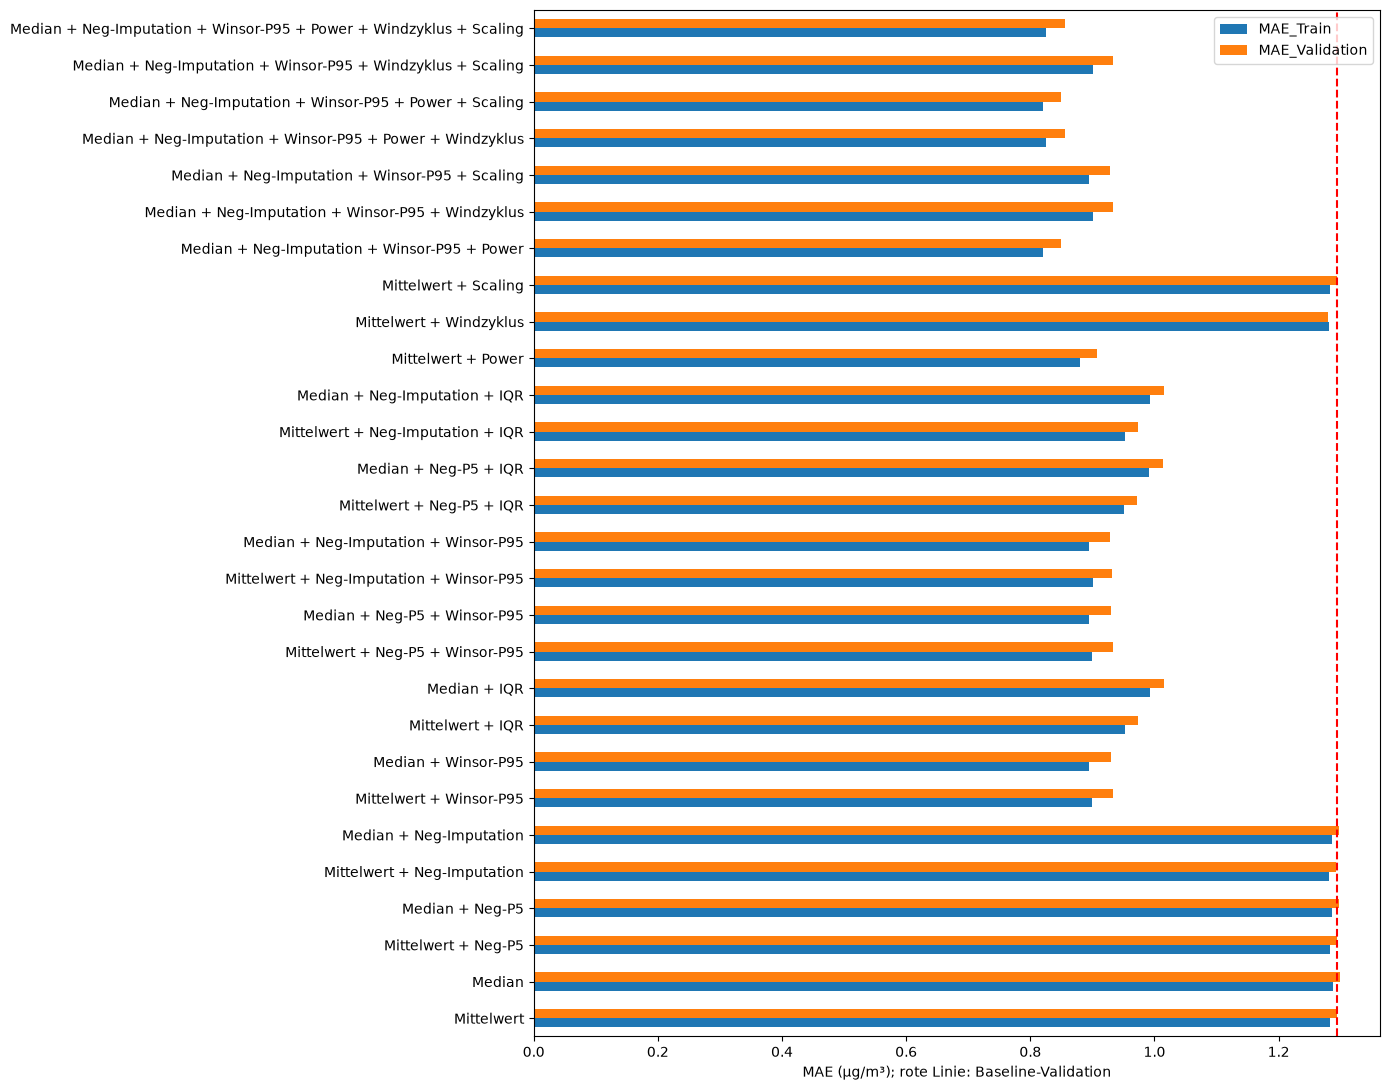

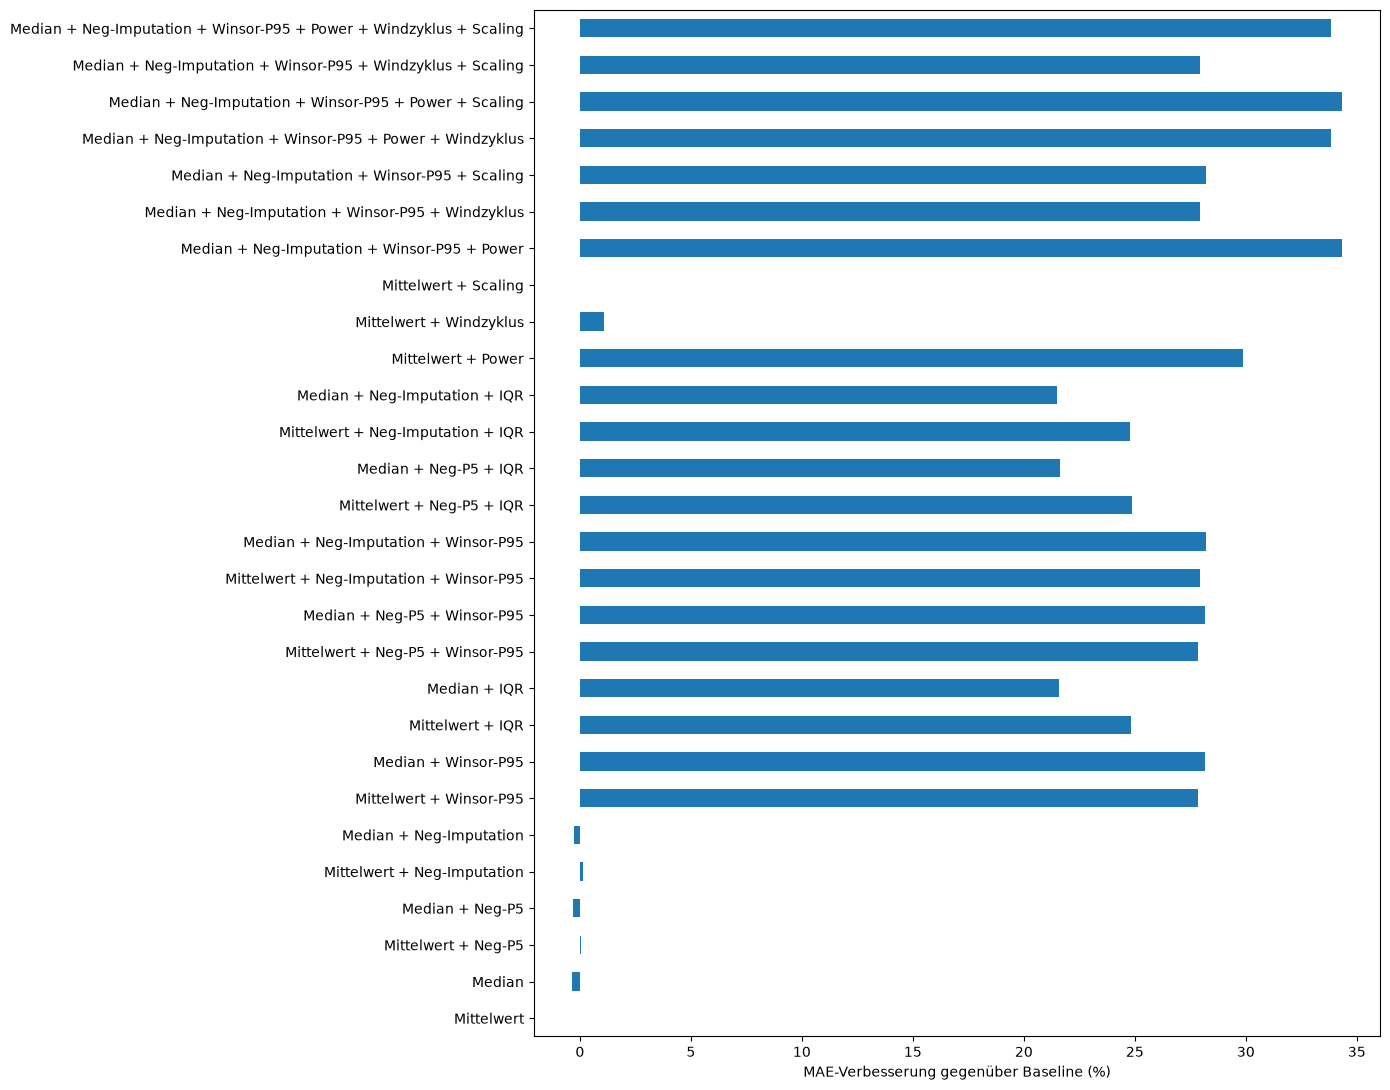

In [26]:
results = pd.DataFrame(log_results).T
results['MAE_Gewinn_abs'] = baseline_mae - results['MAE_Validation']
results['MAE_Gewinn_pct'] = 100 * results['MAE_Gewinn_abs'] / baseline_mae
results['R2_Delta'] = results['R2_Validation'] - baseline_r2
assert len(results) == 28
display(results.sort_values('MAE_Validation'))
results.to_csv('modellvergleich.csv', index_label='Modell')

results[['MAE_Train', 'MAE_Validation']].plot.barh(figsize=(14, 11))
plt.axvline(baseline_mae, color='red', linestyle='--')
plt.xlabel('MAE (µg/m³); rote Linie: Baseline-Validation')
plt.tight_layout()
plt.savefig('modellvergleich_mae.png', bbox_inches='tight')
plt.show()
results['MAE_Gewinn_pct'].plot.barh(figsize=(14, 11))
plt.xlabel('MAE-Verbesserung gegenüber Baseline (%)')
plt.tight_layout()
plt.savefig('modellvergleich_delta.png', bbox_inches='tight')
plt.show()

## 20. Kombinationseffekt und Scaling einordnen

**Quelle:** Ergebnislog und Matplotlib des alten Projekts; zusätzliche einfache Subtraktionen erfüllen das Feedback zu Deltas und Kombinationen.

Positive MAE-Gewinne bedeuten Verbesserung. Die Differenz aus gemeinsamem Gewinn und Summe der Einzelgewinne zeigt, ob die Effekte additiv sind. Sie ist kein Kausalnachweis. Unregularisierte lineare Regression mit Intercept kann affine Skalierung durch andere Koeffizienten ausgleichen; deshalb ist hier kein systematischer Scaling-Gewinn zu erwarten.

In [27]:
gain_winsor = results.loc['Mittelwert + Winsor-P95', 'MAE_Gewinn_abs']
gain_p5 = results.loc['Mittelwert + Neg-P5', 'MAE_Gewinn_abs']
gain_both = results.loc['Mittelwert + Neg-P5 + Winsor-P95', 'MAE_Gewinn_abs']
print('Winsor-Gewinn:', gain_winsor)
print('Neg-P5-Gewinn:', gain_p5)
print('Gemeinsamer Gewinn:', gain_both)
print('Zusätzlicher Kombinationseffekt:', gain_both - gain_winsor - gain_p5)
print('MAE-Änderung durch Scaling allein:',
      results.loc['Mittelwert + Scaling', 'MAE_Validation'] - baseline_mae)
print('MAE-Änderung durch Scaling nach Core + Power:',
      results.loc[core_name + ' + Power + Scaling', 'MAE_Validation']
      - results.loc[core_name + ' + Power', 'MAE_Validation'])

Winsor-Gewinn: 0.36023517316828046
Neg-P5-Gewinn: 0.0006448787294794922
Gemeinsamer Gewinn: 0.36049804254141316
Zusätzlicher Kombinationseffekt: -0.0003820093563468019
MAE-Änderung durch Scaling allein: -1.9984014443252818e-15
MAE-Änderung durch Scaling nach Core + Power: -6.661338147750939e-16


## 21. Auswahl vor dem Test

**Quelle:** Task-1-Notebook, Zelle 19 (`idxmin` zur Auswahl); altes Projekt Zellen 34/36 (benannte Enddaten). **Anpassung:** Der Gewinner wird ausdrücklich benannt und anhand des Ergebnislogs geprüft; bei numerisch gleichem MAE wird die einfachere Variante ohne Scaling gewählt.

Für diese Daten wird die beste Grundvorbereitung mit Power-Transformation weiterverwendet. Die folgende Prüfung stoppt, falls bei einem geänderten Lauf eine andere Variante besser ist. Dann die Tabelle prüfen und die sichtbaren Variablen samt Testschritten anpassen. Kein Refit auf Training plus Validation, damit die Exporte für Task 3 getrennt bleiben.

In [28]:
best_name = core_name + ' + Power'
assert results.loc[best_name, 'MAE_Validation'] <= results['MAE_Validation'].min() + 1e-8
final_model = model_core_power
train_final = train_core_power.copy()
val_final = val_core_power.copy()
print('Ausgewählt:', best_name)
display(results.loc[[best_name]])
results.loc[['Mittelwert', best_name], ['MAE_Train','MAE_Validation','R2_Train','R2_Validation']].to_csv('baseline_und_auswahl.csv', index_label='Modell')

Ausgewählt: Median + Neg-Imputation + Winsor-P95 + Power


,MAE_Train,R2_Train,MAE_Validation,R2_Validation,MAE_Gap,MAE_Gewinn_abs,MAE_Gewinn_pct,R2_Delta
Median + Neg-Imputation + Winsor-P95 + Power,0.821185,0.731913,0.849933,0.727292,0.028749,0.443947,34.31131,0.315604


## 22. Finalen Test vorbereiten

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 36 (0-basiert).

**Originalstelle:**
```python
# Trainieren der Testdaten
test_M1 = rule_based(test_df)
test_M2 = missing_value(test_M1)
test_M3 = feature_removal(test_M2)
```

**Notwendige Anpassung:** Dieselbe explizite Folge benannter Funktionen; nur die tatsächlich ausgewählten Schritte. Ausschließlich bereits berechnete Trainingsgrenzen, Trainingsmedian und PowerTransformer verwenden.

In [29]:
test_df = pd.read_csv('pm25_test.csv')
test_numeric = rule_based(test_df.drop(columns='pm25_target'))
_, test_raw = one_hot_and_align(train_numeric, test_numeric)
test_nan = negative_nan(test_raw)
test_nan_winsor = winsorisation(test_nan, p95)
test_core = missing_value(test_nan_winsor, median_nan_winsor)
test_final = power_apply(test_core, pt_core)
test_pred = final_model.predict(test_final)

# Label nicht auffüllen: nur beobachtete Labels sind bewertbar (Task 1, Zelle 19).
observed = test_df['pm25_target'].notna()
test_mae = mean_absolute_error(test_df.loc[observed, 'pm25_target'], test_pred[observed])
test_r2 = r2_score(test_df.loc[observed, 'pm25_target'], test_pred[observed])
print('Test-MAE:', test_mae, '| Test-R²:', test_r2)
print('Bewertbare Labels:', observed.sum(), 'von', len(test_df))
print('Unbekannte Monate:', set(test_df['year_month']) - set(train_df['year_month']))
pd.DataFrame({'Modell':[best_name], 'MAE':[test_mae], 'R2':[test_r2],
              'Zeilen':[len(test_df)], 'Labels':[observed.sum()]}).to_csv('test_ergebnis.csv',index=False)

Test-MAE: 2.238648556990768 | Test-R²: 0.011271174382902371
Bewertbare Labels: 1419 von 1464
Unbekannte Monate: {'2024-11', '2024-12'}


## 23. Drei CSVs exportieren

**Quelle:** `Altes Projekt mit Feedback/Abgabe_Task_2_Kevin_Izem-2 2/old_Abgabe_Task2.ipynb`, Codezelle 36 (0-basiert).

**Originalstelle:**
```python
train_M5_scaled.to_csv("Task2_Final_preprocessed_train_M5.csv", index=False)
test_M5_scaled.to_csv("Task2_Final_preprocessed_test_M5.csv", index=False)
```

**Notwendige Anpassung:** Zusätzlich Validation exportieren; unveränderte Labels aus den jeweiligen Originaldaten hinzufügen. Kein ID-Feature im Datensatz; Zeilenherkunft in separaten Dateien.

In [30]:
train_export = train_final.copy()
train_export['pm25_target'] = y_train
val_export = val_final.copy()
val_export['pm25_target'] = y_val
test_export = test_final.copy()
test_export['pm25_target'] = test_df['pm25_target']
train_export.to_csv('pm25_preprocessed_train.csv', index=False)
val_export.to_csv('pm25_preprocessed_validation.csv', index=False)
test_export.to_csv('pm25_preprocessed_test.csv', index=False)
test_df[['timestamp']].to_csv('zeilen_test.csv', index_label='source_row')
pd.DataFrame({'prediction':test_pred},index=test_df.index).to_csv('test_vorhersagen.csv',index_label='source_row')
p05.to_csv('trainingsgrenzen_p5.csv',header=['P5'])
pd.Series({'pm25_lowcost':p95}).to_csv('trainingsgrenze_p95.csv',header=['P95'])
median_nan_winsor.to_csv('trainingsmediane_final.csv',header=['Median'])
pd.Series(pt_core.lambdas_,index=power_columns).to_csv('power_parameter.csv',header=['Lambda'])

## 24. Kurze notwendige Abgabekontrollen

**Zusätzlicher Prüfcode, keine behauptete Lab-Kopie.** Diese wenigen Prüfungen sichern die Aufgabenregeln: vollständige Validation/Test, unveränderte Labels und gleiche endliche Feature-Spalten. Die ausführlichen technischen Prüfungen der vorherigen Version sind nicht Teil dieses Lernnotebooks.

In [31]:
assert len(train_export) == 2727 and len(val_export) == 682 and len(test_export) == 1464
assert val_export['pm25_target'].equals(y_val)
assert test_export['pm25_target'].equals(test_df['pm25_target'])
assert train_export.columns.equals(val_export.columns)
assert train_export.columns.equals(test_export.columns)
assert np.isfinite(train_final.to_numpy()).all()
assert np.isfinite(val_final.to_numpy()).all()
assert np.isfinite(test_final.to_numpy()).all()
print('Kontrollen bestanden: Zeilen, Labels und Featureaufbau.')

Kontrollen bestanden: Zeilen, Labels und Featureaufbau.


## 25. Ergebnisse und Learnings

**Quelle:** das tatsächlich berechnete Ergebnislog; Ausgabe nach dem Muster des alten Projekts. Die Texte erläutern die Vergleiche, statt eine neue Auswertungsarchitektur einzuführen.

In [32]:
print('Beste der 28 untersuchten Varianten:', best_name)
print('Validation-MAE:', results.loc[best_name, 'MAE_Validation'])
print('Validation-R²:', results.loc[best_name, 'R2_Validation'])
print('MAE-Gewinn gegenüber derselben Baseline (%):', results.loc[best_name, 'MAE_Gewinn_pct'])
print('Training/Validation-MAE-Abstand:', results.loc[best_name, 'MAE_Gap'])
print('Finaler Test-MAE / R²:', test_mae, test_r2)

Beste der 28 untersuchten Varianten: Median + Neg-Imputation + Winsor-P95 + Power
Validation-MAE: 0.8499333216835651
Validation-R²: 0.7272922193571025
MAE-Gewinn gegenüber derselben Baseline (%): 34.311310064714846
Training/Validation-MAE-Abstand: 0.028748616547263905
Finaler Test-MAE / R²: 2.238648556990768 0.011271174382902371


- Eine vollständige Baseline verhindert, dass eine künstlich schwache Featureauswahl als Vorbereitungserfolg erscheint.
- Die ungefilterte NO-P5-Grenze ist negativ. Eine Negativwertkorrektur darf deshalb nur gültige Trainingsmessungen als Referenz verwenden.
- Winsorisierung und IQR-Imputation sind verschiedene Eingriffe. Ihre Einzelwirkungen und Kombinationen werden auf demselben Split geprüft.
- Die stufenweise Auswahl ist lesbar, kann aber eine Kombination übersehen, deren Grundvorbereitung allein schwächer ist. Diese Version beansprucht keine globale Auswahl aus allen 144 früheren Kombinationen.
- Scaling ändert bei unregularisierter OLS den darstellbaren Modellraum nicht; Unterschiede in Rundungsgröße sind kein inhaltlicher Gewinn.
- Der Test war bereits bekannt. Zufällige zeitliche Mischung, mehrfach verwendete Validation und unbekannte Testmonate begrenzen die Übertragbarkeit. Geringes oder negatives Test-R² darf nicht durch gute Validierungswerte verdeckt werden.
- Keine Präsentation in dieser Abgabe. Die ältere Präsentation gehört nicht zum neuen Notebookstand.

### Einordnung des ausgeführten Ergebnisses

Die Baseline erreicht Validation-MAE **1,2939** und R² **0,4117**. Die ausgewählte Variante **Median + Neg-Imputation + Winsor-P95 + Power** erreicht MAE **0,8499** und R² **0,7273**: **34,31 % weniger MAE**, keine „34 % höhere Genauigkeit“. Ihr Trainings-MAE ist **0,8212**; der Abstand zur Validation beträgt **0,0287**.

Winsor-P95 allein senkt bei Mittelwertimputation den MAE auf **0,9336**, IQR allein auf **0,9727**. Neg-P5 allein bringt nur etwa **0,000645** Verbesserung. Zusammen mit Winsor beträgt der Gewinn **0,360498**, weniger als die Summe der beiden Einzelgewinne (**0,360880**). Die Wirkungen sind also nicht einfach addierbar. Median allein ist etwas schlechter als Mittelwert, innerhalb der besten Grundkombination jedoch besser. Deshalb reicht es nicht, nur die besten Einzelschritte aneinanderzureihen.

Power verbessert die gewählte Grundkombination von **0,9289** auf **0,8499**. Windzyklus zusätzlich zu Power verschlechtert den MAE auf **0,8563**, obwohl R² auf **0,7305** steigt. Da MAE das vorher festgelegte Auswahlkriterium ist, wird Windzyklus nicht übernommen. Scaling bringt nur Rundungsunterschiede und entfällt ebenfalls.

Im bereits bekannten offiziellen Test beträgt der MAE **2,2386**, R² nur **0,0113** (1.419 vorhandene Labels bei 1.464 unverändert erhaltenen Zeilen). Das ist eine deutliche Verschlechterung gegenüber der Validation. Zeitliche Verteilungsunterschiede und im Training unbekannte Monatskategorien sind mögliche Erklärungen, hier jedoch nicht als Ursache nachgewiesen. Das Ergebnis belegt keine zuverlässige Übertragung auf spätere Zeiträume. Es wird offen berichtet und nicht für eine erneute Auswahl genutzt.
